# Twiss benchmark — magnetic_2 (ВРЕМЕННЫЙ ноутбук для ревью)

Решётка `examples/lattices/magnetic_2.opt`: дейтрон, E_kin = 270 МэВ, C = 117.388 м, 16 секторных диполей без краевых углов, секступоли выключены.
Коды: **Bell**, **OptiM** (CLI), **COSY Infinity 10.2**, **MAD-X** (TWISS и PTC).
Ноутбук только читает файлы, которые создали `*/run.jl`, `plot_compare.jl`, `compare.jl`, `bell/linear_routes.jl`; сам ничего не пересчитывает.
Комментарии можно писать прямо в markdown-ячейки.

In [1]:
using Printf
const TW = @__DIR__   # benchmarks/twiss
showpng(f) = display("image/png", read(joinpath(TW, f)))
function showcsv(f)
    L = readlines(joinpath(TW, f)); h = split(L[1], ",")
    println(join(rpad.(h, 16))); for l in L[2:end]; println(join(rpad.(split(l, ","), 16))); end
end

showcsv (generic function with 1 method)

## 1. Как Bell считает линейную оптику (поток вызовов)

**Основной путь (`bell/run.jl`, как в examples/10):**
1. `convert_optim(opt, bell)` — разбор `.opt` OptiM → файл структуры `.bell` (энергия, масса, элементы, последовательность).
2. `load_structure(bell)` → `Lattice` (элементы `Drift/Quadrupole/SBend/Sextupole/...`, `RefParticle`).
3. `ring_matrix(lat)` = произведение `linear_matrix(e, ref)` по элементам. Для каждого элемента: `R = exp(L·S·A)`, где `A` = гессиан `hamiltonian(e, ref)` (TaylorSeries) в нуле, `S` — симплектическая форма. Без учебных формул; `S·A` кешируется.
4. `periodic_optics(R, ref, C)` — β, α, μ по блокам 2×2, периодическая дисперсия `(I−R4)⁻¹R[1:4,6]`, α_c = 1/γ² − (l|δ)/C.
5. `optics_along(lat, po; ds=0.02)` — каждый элемент режется на срезы ≤2 см, для каждого среза снова `linear_matrix(e, ref, L/n)` (матричная экспонента); β, α переносятся 2×2-формулой, фаза накапливается, D = R·(D4,0,1). Отсюда целые Q, графики, проверка замыкания.

**Путь «третьего порядка» (`ring_metrics`):** `observables(lat)` → `ring_lie_factor(lat)` (произведение Ли-факторов, Dragt–Finn) → `F.R` (линейная часть) → `periodic_optics`; плюс `factor_to_map` → полиномиальная карта → `chromaticity_orders` (ξ1, ξ2), `path_expansion` (α0, α1), `dispersion_orders` (D2). Для линейной оптики это избыточно — нужен только `F.R`.

**Путь DATracking:** `one_turn_map_da(lat, N)` = композиция `element_da_map(e, ref, N)` = exp(−L:H:) от полного гамильтониана (`da/fields` (equations of motion on DA)) в DA порядка N; линейная матрица = `DiffAlgebra.linear_part(M)`. При N=1 это фактически та же матричная экспонента, но в собственной DA-арифметике.

## 2. Три маршрута к одно-оборотной матрице (каждый в отдельном процессе Julia)
first_s — первый вызов (с JIT), warm_s — прогретый (кеши гессианов/карт очищены), process_s — весь процесс. max_abs_dR — макс. отличие матрицы от `ring_matrix`.

In [2]:
showcsv("bell/linear_routes.csv")

route           using_s         first_s         warm_s          Qx_frac         Qy_frac         betx0           alfx0           bety0           alfy0           Dx0             Dpx0            alpha_c         max_abs_dR_vs_matrixprocess_s       
matrix          0.9720          4.7241          0.00960         0.4617201498668020.4613373230490819.3675224161454-0.0002519117766501744.054470469005  -0.0001881504893841380.0110941104046135-0.0005061660507425410.2304702821566740.000e+00       7.841           
dragtfinn       1.0250          5.4090          0.08489         0.4617201498668030.46133732304908519.3675224161465-0.0002519117766499484.05447046900551-0.00018815048938070.0110941104046076-0.0005061660507424660.2304702821566722.771e-13       9.819           
flow1           0.9830          3.8026          0.00172         0.4617201498668050.46133732304908519.3675224161474-0.0002519117766492574.05447046900552-0.0001881504893827770.0110941104045983-0.0005061660507418020.2304702821566732.016e-1

## 3. Twiss каждого кода (своими данными)

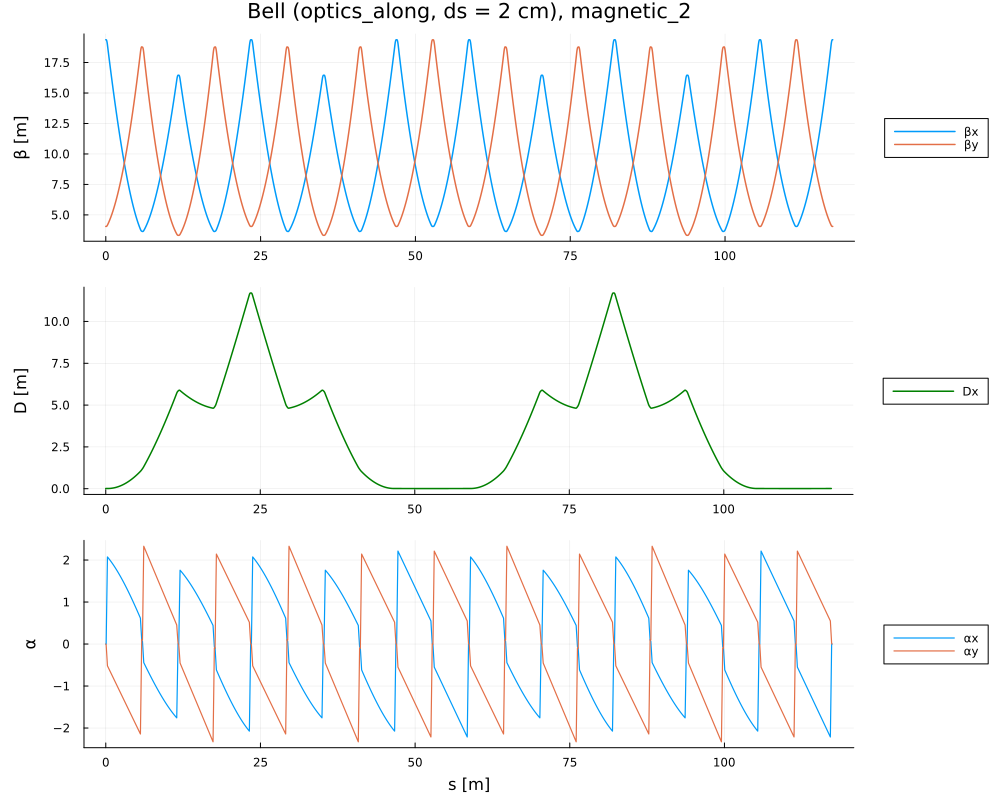

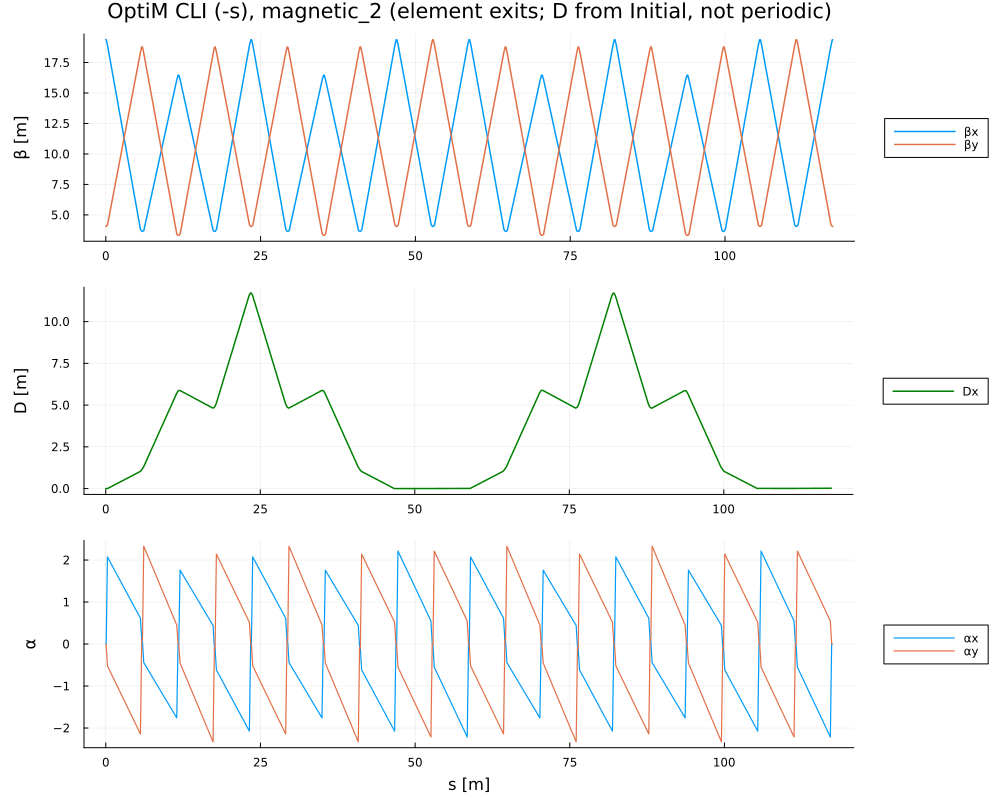

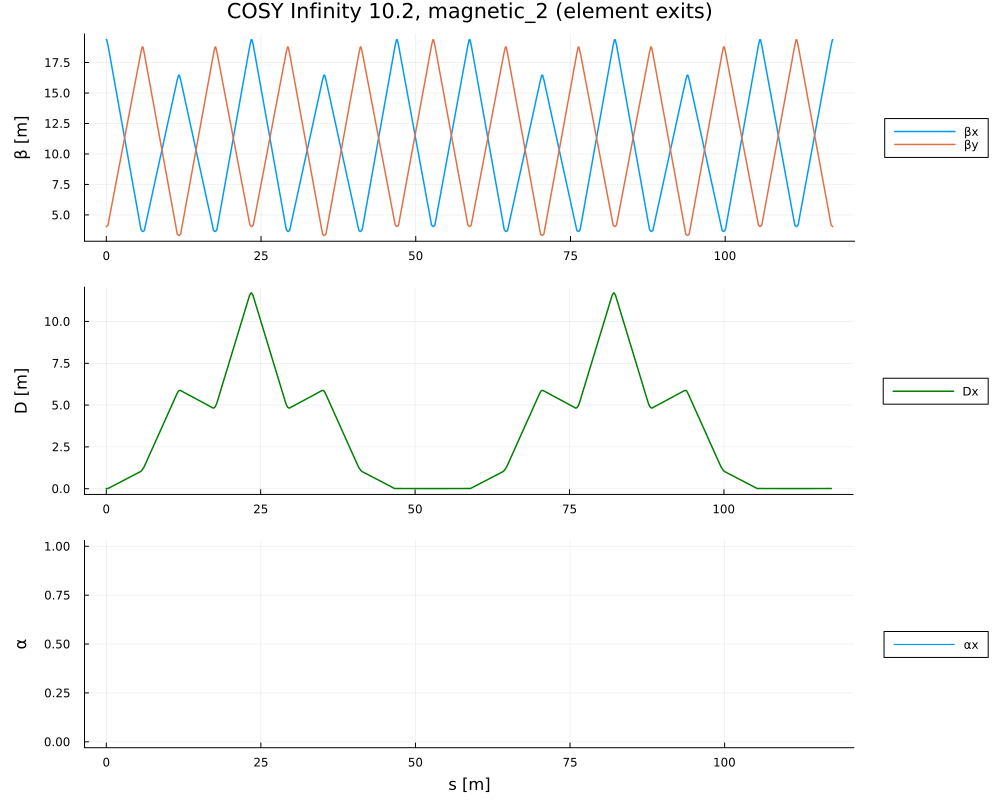

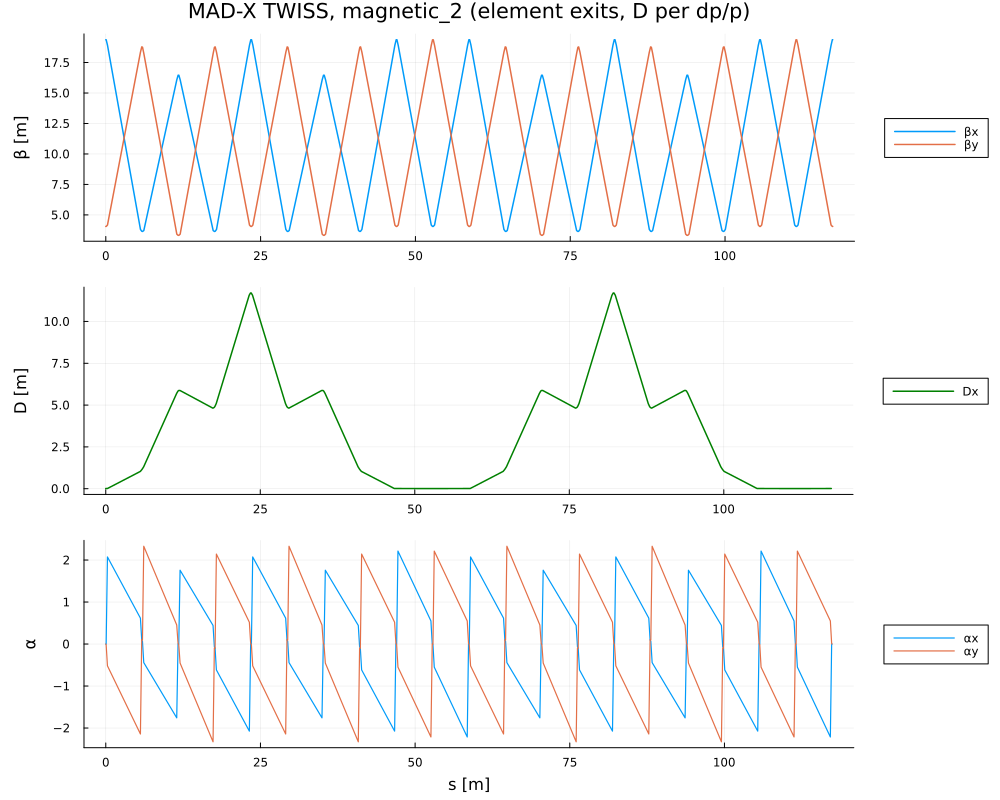

In [3]:
for f in ("bell/twiss_bell.png", "optim/twiss_optim.png", "cosy/twiss_cosy.png", "madx/twiss_madx.png"); showpng(f); end

## 4. Наложение всех кодов
На глаз кривые совпадают; видно только смещение D у OptiM (CLI стартует дисперсию с `Initial:` D=0, а не с периодического решения).

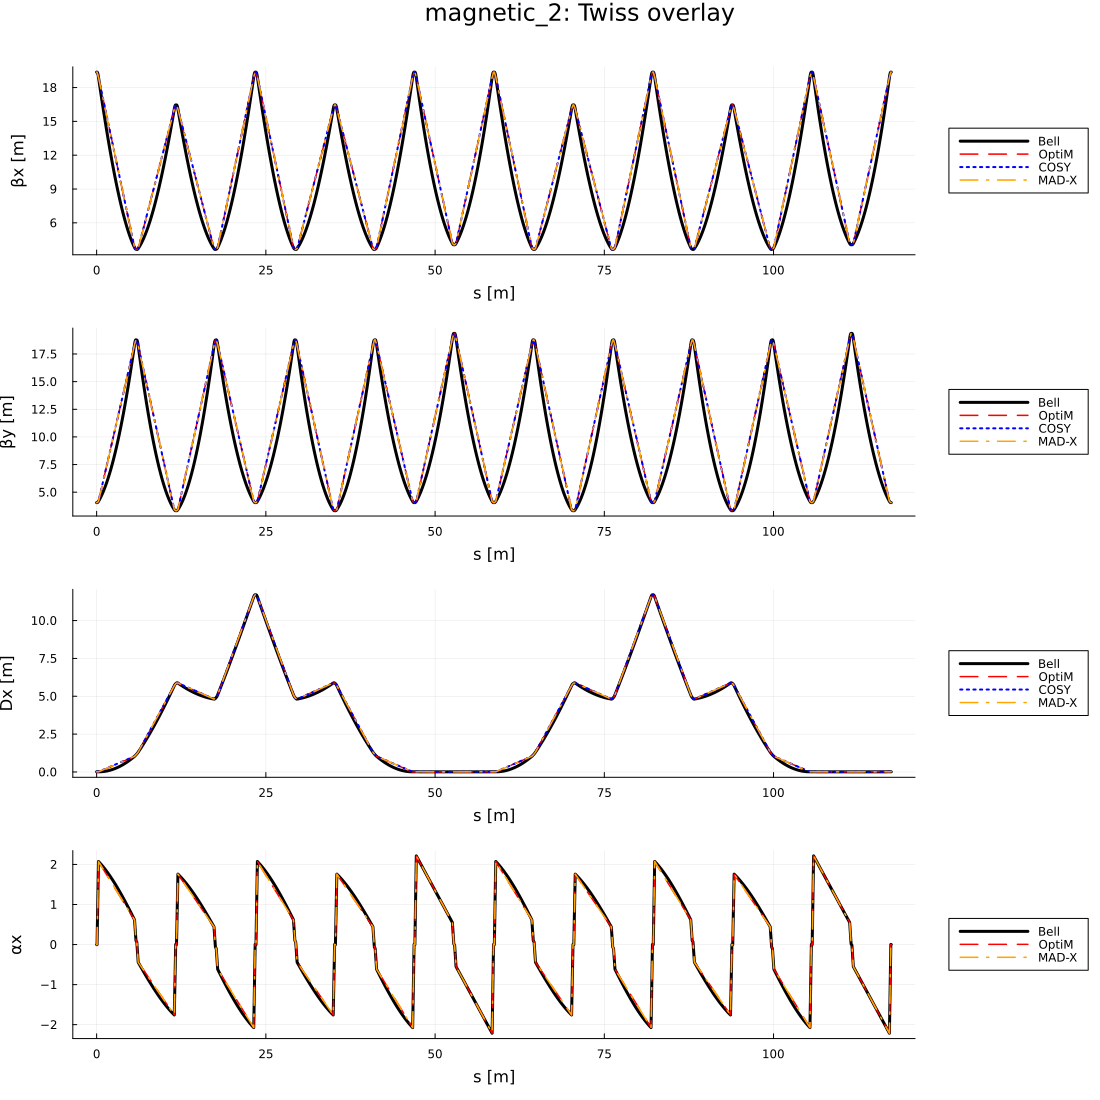

In [4]:
showpng("twiss_overlay.png")

## 5. Разности относительно Bell (в точках выхода элементов)
β — относительная разность, α и D — абсолютная. У OptiM в таблице 6 значащих цифр → шум ~1e-6. У COSY α не выводится.

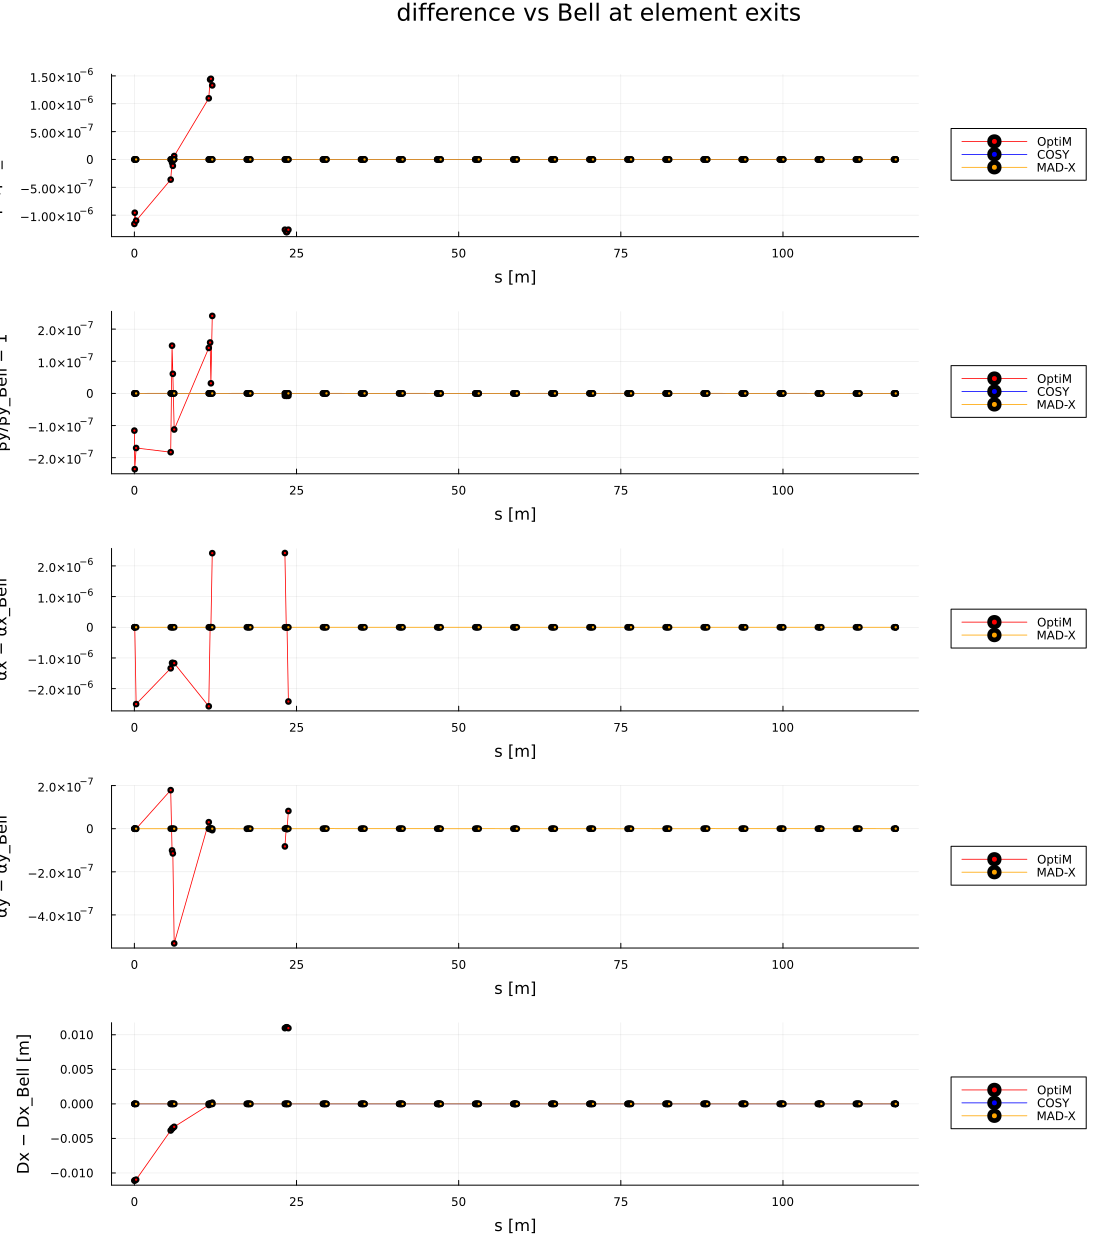

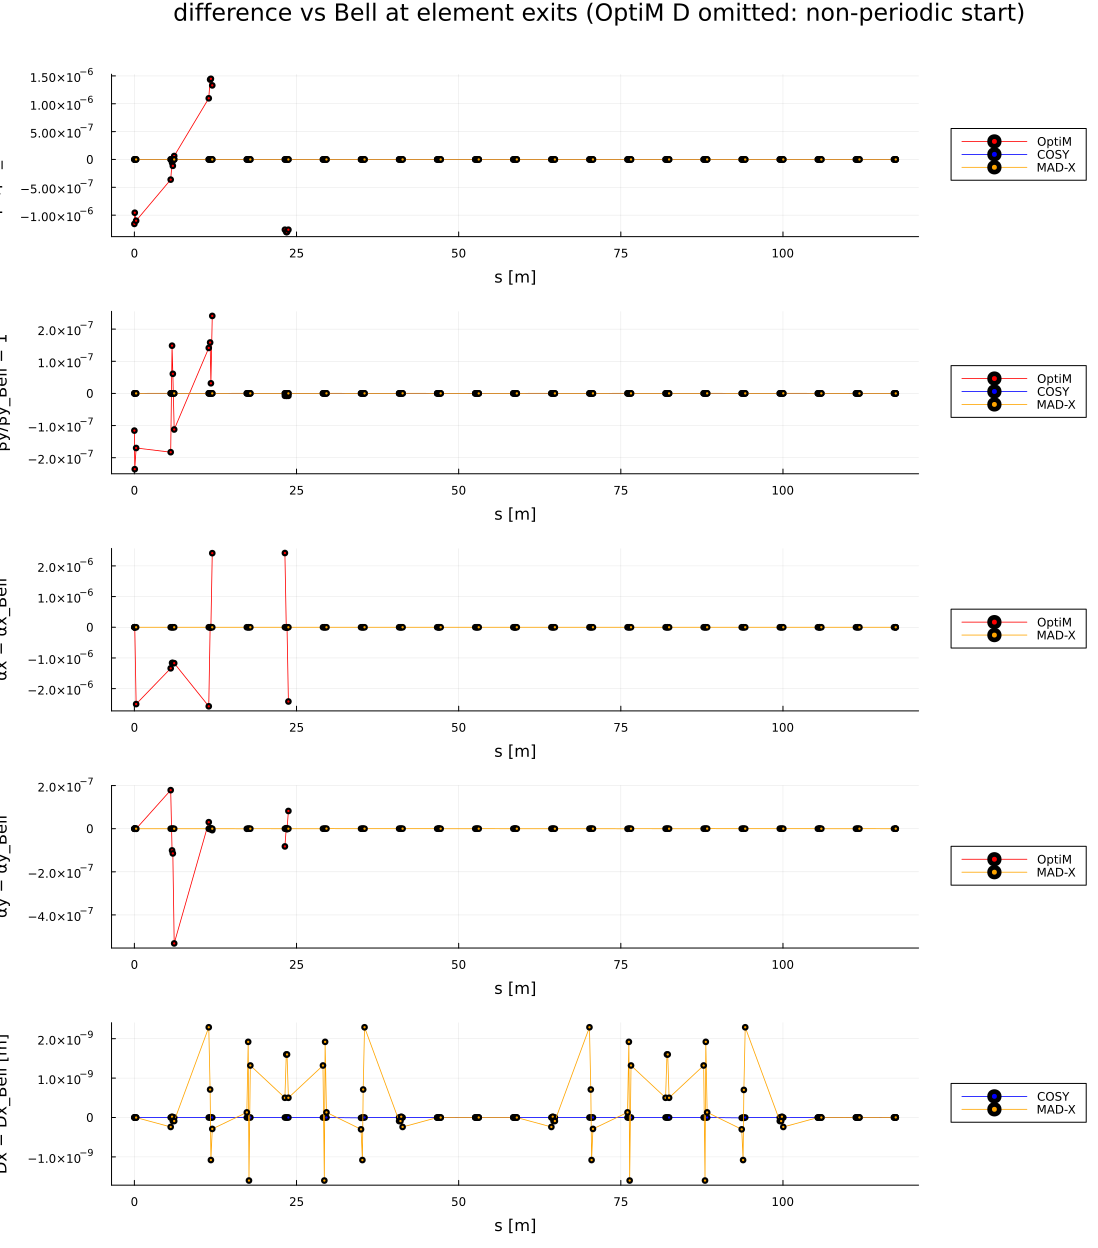

code            max_rel_dbetx   max_rel_dbety   max_abs_dalfx   max_abs_dalfy   max_abs_dDx_m   npoints         
optim           1.448e-06       2.411e-07       2.576e-06       5.322e-07       1.109e-02       86              
cosy            0.000e+00       2.466e-12       NaN             NaN             1.000e-11       85              
madx            2.530e-10       2.612e-10       4.800e-10       4.400e-10       2.290e-09       86              


In [5]:
showpng("twiss_diff_vs_bell.png"); showpng("twiss_diff_vs_bell_no_optimD.png"); showcsv("twiss_diff_summary.csv")

## 6. Скаляры и тайминги (из `compare.jl`)
ξy: MAD-X/OptiM ≠ Bell/COSY — по словам пользователя, из-за учёта краевого поля диполей в MAD-X/OptiM; отложено.

In [6]:
print(read(joinpath(TW, "comparison.md"), String))

# magnetic_2 — cross-code values (generated by compare.jl from actual runs)

Units: m; D per delta_p = dp/p; xi = dQ/d(dp/p). Bell is the column the others are compared to (rel. diff in brackets).

| quantity | optim | bell | cosy | madx |
|---|---|---|---|---|
| C_m | 117.3883 (3.4e-08) | 117.388296 | 117.388296 | 117.388296 |
| Qx | 2.46172 (-6.1e-08) | 2.46172015 | — | 2.46172015 (5.3e-11) |
| Qy | 2.461337 (-1.3e-07) | 2.46133732 | — | 2.46133732 (-2.0e-11) |
| Qx_frac | — | — | 0.46172015 (-6.5e-12) | — |
| Qy_frac | — | — | 0.461337323 (-2.2e-12) | — |
| xi_x | — | -1.46153752 | -1.46153572 (-1.2e-06) | -1.46153318 (-3.0e-06) |
| xi_y | — | -2.22548794 | -2.22548493 (-1.4e-06) | -1.81706042 (-1.8e-01) |
| xi_x_ptc_exact | — | — | — | -1.46153572 |
| xi_y_ptc_exact | — | — | — | -1.8170633 |
| alpha_c | — | 0.230470282 | 0.230470282 | 0.230470282 (1.9e-10) |
| eta_slip | — | -0.533688628 | -0.533688628 | — |
| eta_slip_ptc | — | — | — | -0.533688628 |
| betx0_m | 19.3675 (-1.2e-06

## 7. Заметки для ревью
- Время Bell «целиком» ≈ 11–15 с: `using Bell` ~1 с, Plots ~3–4 с (только для картинок), JIT первых вызовов ~7 с, сам расчёт 0.002–0.13 с.
- (место для комментариев)